In [2]:

!git clone --depth 1 https://github.com/AhmedkKazak/brain-tumor-detection.git


Cloning into 'brain-tumor-detection'...
remote: Enumerating objects: 7039, done.
remote: Counting objects: 100% (7039/7039), done.
remote: Compressing objects: 100% (7035/7035), done.
remote: Total 7039 (delta 0), reused 7038 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (7039/7039), 190.08 MiB | 47.58 MiB/s, done.
Updating files: 100% (7211/7211), done.


In [3]:
!git -C /kaggle/working/brain-tumor-detection switch -c ahmed-tensorflow

Switched to a new branch 'ahmed-tensorflow'


In [4]:
from pathlib import Path

repo = Path("/kaggle/working/brain-tumor-detection")

print("Current branch:")
!git -C /kaggle/working/brain-tumor-detection branch --show-current

print("\nDataset folders:")
for folder in sorted((repo / "data").iterdir()):
    if folder.is_dir():
        print(folder.name)

print("\nPyTorch Notebook:")
print((repo / "notebooks/pytorch_T35.ipynb").exists())

Current branch:
ahmed-tensorflow

Dataset folders:
Testing
Training

PyTorch Notebook:
True


In [7]:
import json
import hashlib
import numpy as np

from pathlib import Path
from tqdm.auto import tqdm
from torchvision.datasets import ImageFolder
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path("/kaggle/working/brain-tumor-detection")
TRAIN_DIR = ROOT / "data/Training"
TEST_DIR = ROOT / "data/Testing"

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
SEED = 42

train_data = ImageFolder(TRAIN_DIR)
test_data = ImageFolder(TEST_DIR)

assert train_data.classes == CLASS_NAMES
assert test_data.classes == CLASS_NAMES

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

train_hashes = [
    sha256_file(p)
    for p, _ in tqdm(train_data.samples, desc="Hash Training")
]

test_hashes = [
    sha256_file(p)
    for p, _ in tqdm(test_data.samples, desc="Hash Testing")
]

labels = np.array(train_data.targets)

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_idx, val_idx = next(
    sgkf.split(
        np.arange(len(labels)),
        labels,
        groups=train_hashes
    )
)

assert not (
    set(np.array(train_hashes)[train_idx])
    & set(np.array(train_hashes)[val_idx])
)

manifest = {
    "classes": CLASS_NAMES,
    "train": [
        Path(train_data.samples[i][0]).relative_to(TRAIN_DIR).as_posix()
        for i in train_idx
    ],
    "val": [
        Path(train_data.samples[i][0]).relative_to(TRAIN_DIR).as_posix()
        for i in val_idx
    ],
    "test": [
        Path(p).relative_to(TEST_DIR).as_posix()
        for p, _ in test_data.samples
    ]
}

split_path = ROOT / "notebooks/splits_T35.json"

with open(split_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_data))

print("Exact duplicates within Training:",
      len(train_hashes) - len(set(train_hashes)))

print("Training/Testing shared hashes:",
      len(set(train_hashes) & set(test_hashes)))

print("Saved:", split_path)

Hash Training:   0%|          | 0/5600 [00:00<?, ?it/s]

Hash Testing:   0%|          | 0/1600 [00:00<?, ?it/s]

Training: 4481
Validation: 1119
Testing: 1600
Exact duplicates within Training: 171
Training/Testing shared hashes: 0
Saved: /kaggle/working/brain-tumor-detection/notebooks/splits_T35.json


In [8]:
import tensorflow as tf
import json
from pathlib import Path

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

ROOT = Path("/kaggle/working/brain-tumor-detection")

with open(ROOT / "notebooks/splits_T35.json") as f:
    splits = json.load(f)

IMAGE_SIZE = 224
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
class_to_idx = {name: i for i, name in enumerate(CLASS_NAMES)}

def build_paths(split):
    folder = "Testing" if split == "test" else "Training"

    paths = [
        str(ROOT / "data" / folder / p)
        for p in splits[split]
    ]

    labels = [
        class_to_idx[Path(p).parent.name]
        for p in splits[split]
    ]

    return paths, labels

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image, [IMAGE_SIZE, IMAGE_SIZE],
        method="bilinear"
    )

    return image, label

def make_dataset(split, shuffle=False):
    paths, labels = build_paths(split)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(
            len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset("train", shuffle=True)
val_ds = make_dataset("val")
test_ds = make_dataset("test")

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", float(tf.reduce_min(images)),
      float(tf.reduce_max(images)))
print("Train batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches:", len(test_ds))

TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


I0000 00:00:1792959285.711980      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792959285.715763      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Pixel range: 0.0 255.0
Train batches: 281
Validation batches: 70
Test batches: 100


In [9]:
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

# 1. Data Augmentation
augmentation = keras.Sequential([
    layers.RandomRotation(
        factor=8/360,
        fill_mode="constant",
        fill_value=0.0
    ),
    layers.RandomTranslation(
        height_factor=0.03,
        width_factor=0.03,
        fill_mode="constant",
        fill_value=0.0
    )
], name="medical_augmentation")

# 2. Training Preprocessing
def preprocess_train(images, labels):
    images = augmentation(images, training=True)
    images = keras.applications.resnet50.preprocess_input(images)
    return images, labels

# 3. Validation / Testing Preprocessing
def preprocess_eval(images, labels):
    images = keras.applications.resnet50.preprocess_input(images)
    return images, labels

# 4. Apply Pipelines
tf_train_ds = train_ds.map(
    preprocess_train,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

tf_val_ds = val_ds.map(
    preprocess_eval,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

tf_test_ds = test_ds.map(
    preprocess_eval,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

# 5. Verify
images, labels = next(iter(tf_train_ds))

print("Training batch:", images.shape)
print("Labels:", labels.shape)
print("Min pixel value:", float(tf.reduce_min(images)))
print("Max pixel value:", float(tf.reduce_max(images)))
print("Preprocessing ready!")

Training batch: (16, 224, 224, 3)
Labels: (16,)
Min pixel value: -123.68000030517578
Max pixel value: 151.06100463867188
Preprocessing ready!


In [10]:
from tensorflow import keras
from tensorflow.keras import layers

# 1. Load pretrained ResNet50
base_model = keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# 2. Freeze pretrained layers
base_model.trainable = False

# 3. Build classification model
inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="BrainTumor_ResNet50"
)

# 4. Compile
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Model summary
model.summary()

print("\nModel built successfully!")
print("Trainable parameters:",
      sum(int(tf.size(w)) for w in model.trainable_weights))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "BrainTumor_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)


Model built successfully!
Trainable parameters: 8196


In [11]:
from pathlib import Path
from tensorflow import keras

WORK_DIR = Path("/kaggle/working/T35_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)

HEAD_MODEL_PATH = WORK_DIR / "resnet50_head_best.keras"

head_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(HEAD_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

head_history = model.fit(
    tf_train_ds,
    validation_data=tf_val_ds,
    epochs=6,
    callbacks=head_callbacks,
    verbose=1
)

print("\nStage 1 completed!")
print("Best Validation Accuracy:",
      max(head_history.history["val_accuracy"]))

print("Best Validation Loss:",
      min(head_history.history["val_loss"]))

print("Model saved to:", HEAD_MODEL_PATH)

Epoch 1/6
  3/281 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - accuracy: 0.2639 - loss: 1.8039 

I0000 00:00:1792959824.002089     182 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.6492 - loss: 0.8583
Epoch 1: val_loss improved from None to 0.28675, saving model to /kaggle/working/T35_work/resnet50_head_best.keras

Epoch 1: finished saving model to /kaggle/working/T35_work/resnet50_head_best.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 44s 115ms/step - accuracy: 0.7652 - loss: 0.5928 - val_accuracy: 0.8865 - val_loss: 0.2868
Epoch 2/6
280/281 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8676 - loss: 0.3643
Epoch 2: val_loss improved from 0.28675 to 0.27346, saving model to /kaggle/working/T35_work/resnet50_head_best.keras

Epoch 2: finished saving model to /kaggle/working/T35_work/resnet50_head_best.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - accuracy: 0.8697 - loss: 0.3525 - val_accuracy: 0.8901 - val_loss: 0.2735
Epoch 3/6
280/281 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8817 - loss: 0.3069
Epoch 3: val_loss did not improve from 0.27346
281/281 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.8822 -

In [12]:
# ==========================================
# Stage 2: Fine-tuning ResNet50
# ==========================================

from tensorflow import keras
from tensorflow.keras import layers

# 1. Unfreeze backbone
base_model.trainable = True

# 2. Fine-tune only the final ResNet stage
for layer in base_model.layers:
    layer.trainable = (
        layer.name.startswith("conv5_")
        and not isinstance(layer, layers.BatchNormalization)
    )

# 3. Recompile after changing trainable layers
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 4. Save best fine-tuned model
FINETUNE_MODEL_PATH = (
    WORK_DIR / "resnet50_finetuned_best.keras"
)

finetune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(FINETUNE_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# 5. Train
finetune_history = model.fit(
    tf_train_ds,
    validation_data=tf_val_ds,
    epochs=12,
    callbacks=finetune_callbacks,
    verbose=1
)

# 6. Results
print("\nFine-tuning completed!")

print(
    "Best Validation Accuracy:",
    max(finetune_history.history["val_accuracy"])
)

print(
    "Best Validation Loss:",
    min(finetune_history.history["val_loss"])
)

print("Saved model:", FINETUNE_MODEL_PATH)

Epoch 1/12
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.9186 - loss: 0.2199
Epoch 1: val_loss improved from None to 0.20739, saving model to /kaggle/working/T35_work/resnet50_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/T35_work/resnet50_finetuned_best.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 49s 129ms/step - accuracy: 0.9232 - loss: 0.2046 - val_accuracy: 0.9294 - val_loss: 0.2074
Epoch 2/12
280/281 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9435 - loss: 0.1507
Epoch 2: val_loss improved from 0.20739 to 0.17404, saving model to /kaggle/working/T35_work/resnet50_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/T35_work/resnet50_finetuned_best.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 26s 91ms/step - accuracy: 0.9467 - loss: 0.1388 - val_accuracy: 0.9455 - val_loss: 0.1740
Epoch 3/12
280/281 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.9684 - loss: 0.0810
Epoch 3: val_loss improved from 0.17404 to 0.14742, saving model to /kaggle/w

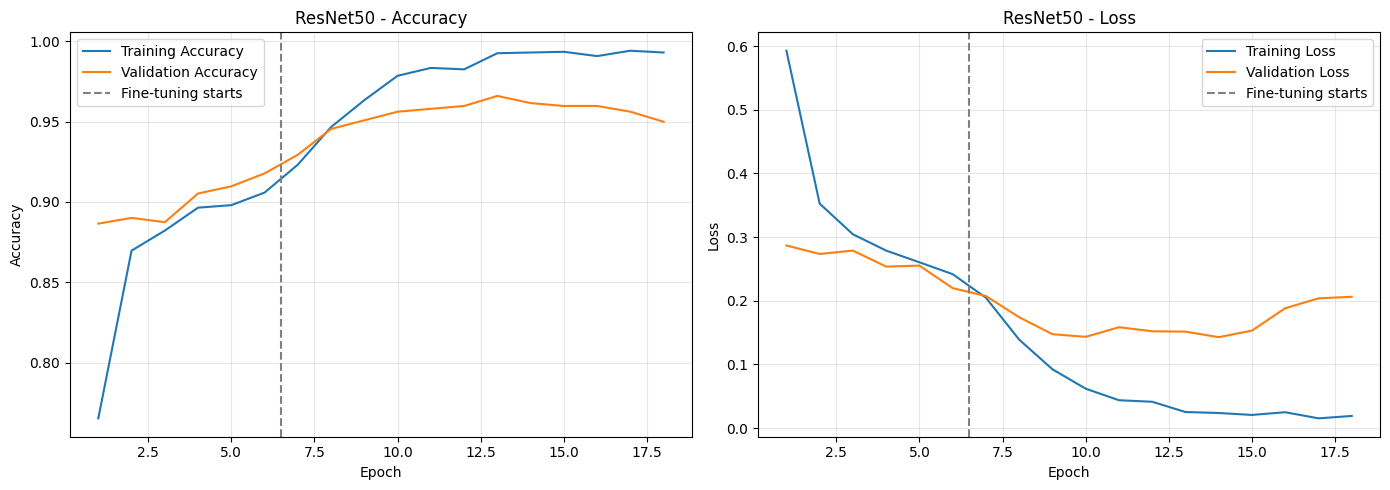

Training curves and CSV saved successfully!


In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# Combine both training stages
head = pd.DataFrame(head_history.history)
fine = pd.DataFrame(finetune_history.history)

head["stage"] = "Feature Extraction"
fine["stage"] = "Fine-tuning"

history_df = pd.concat([head, fine], ignore_index=True)
history_df["epoch"] = range(1, len(history_df) + 1)

# Save training history
history_df.to_csv(
    WORK_DIR / "tensorflow_training_history_T35.csv",
    index=False
)

boundary = len(head)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curve
axes[0].plot(
    history_df["epoch"],
    history_df["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].axvline(
    boundary + 0.5,
    linestyle="--",
    color="gray",
    label="Fine-tuning starts"
)

axes[0].set_title("ResNet50 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss curve
axes[1].plot(
    history_df["epoch"],
    history_df["loss"],
    label="Training Loss"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

axes[1].axvline(
    boundary + 0.5,
    linestyle="--",
    color="gray",
    label="Fine-tuning starts"
)

axes[1].set_title("ResNet50 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    WORK_DIR / "tensorflow_training_curves_T35.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Training curves and CSV saved successfully!")

Best fine-tuned model loaded!
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.9375 - loss: 0.5999
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step

========== TEST RESULTS ==========
Test Loss:      0.5999
Test Accuracy:  0.9375
Precision:      0.9397
Recall:         0.9375
F1 Score:       0.9365

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      glioma       0.96      0.82      0.88       400
  meningioma       0.88      0.95      0.91       400
     notumor       0.93      1.00      0.96       400
   pituitary       0.98      0.98      0.98       400

    accuracy                           0.94      1600
   macro avg       0.94      0.94      0.94      1600
weighted avg       0.94      0.94      0.94      1600



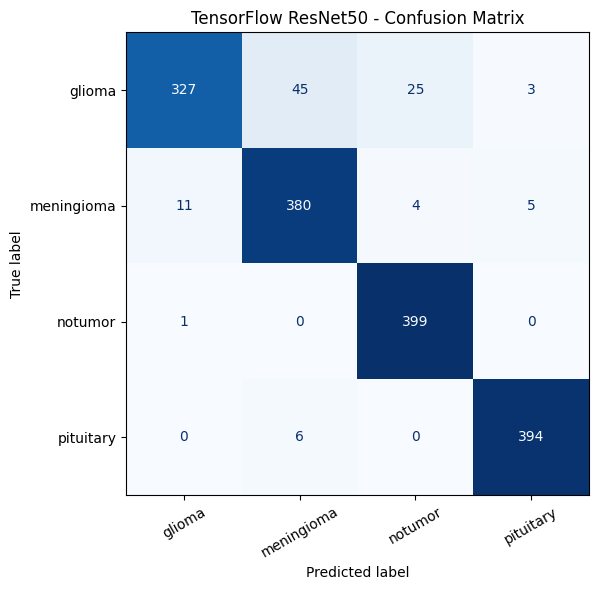


Evaluation results saved successfully!


In [14]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =========================================
# 1. Load best fine-tuned model
# =========================================

best_model = keras.models.load_model(
    str(FINETUNE_MODEL_PATH)
)

print("Best fine-tuned model loaded!")

# =========================================
# 2. Evaluate on Test Set
# =========================================

test_loss, test_accuracy = best_model.evaluate(
    tf_test_ds,
    verbose=1
)

# =========================================
# 3. Get true labels and predictions
# =========================================

y_true = np.concatenate([
    labels.numpy()
    for images, labels in tf_test_ds
])

y_probs = best_model.predict(
    tf_test_ds,
    verbose=1
)

y_pred = np.argmax(y_probs, axis=1)

assert len(y_true) == len(y_pred) == 1600

# =========================================
# 4. Calculate Metrics
# =========================================

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=list(range(4)),
    average="macro",
    zero_division=0
)

print("\n========== TEST RESULTS ==========")

print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Precision:      {precision:.4f}")
print(f"Recall:         {recall:.4f}")
print(f"F1 Score:       {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(4)),
    target_names=CLASS_NAMES,
    zero_division=0
)

print(report)

# =========================================
# 5. Confusion Matrix
# =========================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(4))
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("TensorFlow ResNet50 - Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    WORK_DIR / "tensorflow_confusion_matrix_T35.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# =========================================
# 6. Save Results
# =========================================

metrics = {
    "framework": "tensorflow",
    "architecture": "ResNet50",
    "test_samples": len(y_true),
    "test_loss": float(test_loss),
    "accuracy": float(accuracy),
    "precision_macro": float(precision),
    "recall_macro": float(recall),
    "f1_macro": float(f1)
}

with open(WORK_DIR / "tensorflow_metrics_T35.json", "w") as f:
    json.dump(metrics, f, indent=4)

predictions_df = pd.DataFrame({
    "true_label": [CLASS_NAMES[i] for i in y_true],
    "predicted_label": [CLASS_NAMES[i] for i in y_pred],
    "confidence": np.max(y_probs, axis=1)
})

predictions_df.to_csv(
    WORK_DIR / "tensorflow_predictions_T35.csv",
    index=False
)

print("\nEvaluation results saved successfully!")

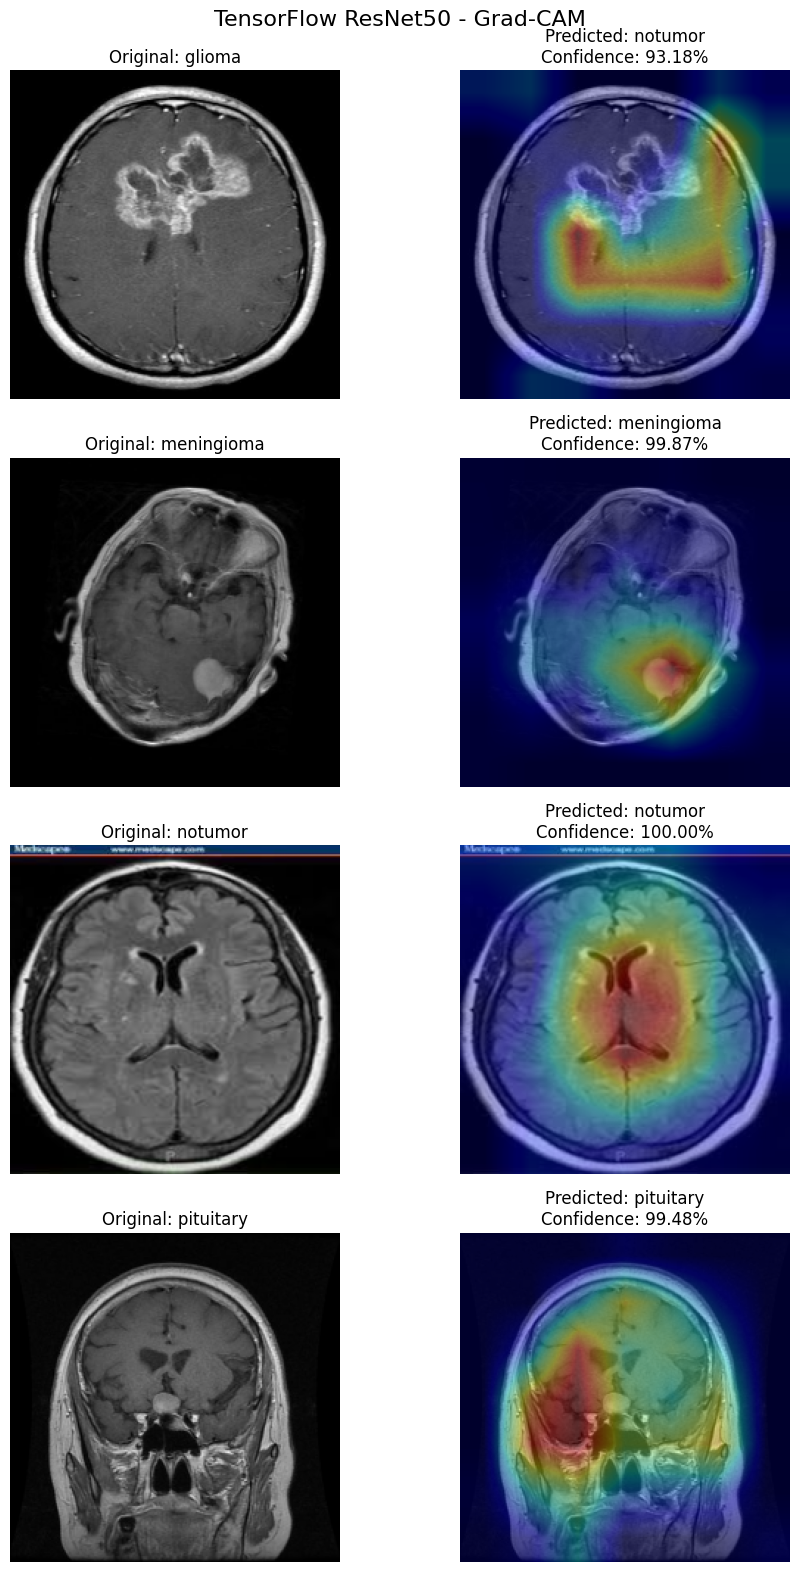

Grad-CAM saved successfully!


In [15]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow import keras

# ==========================================
# 1. Load trained model
# ==========================================

best_model = keras.models.load_model(
    str(FINETUNE_MODEL_PATH)
)

backbone = best_model.get_layer("resnet50")

# ==========================================
# 2. Grad-CAM feature extractor
# ==========================================

last_conv_layer = backbone.get_layer(
    "conv5_block3_out"
)

grad_model = keras.Model(
    inputs=backbone.input,
    outputs=[
        last_conv_layer.output,
        backbone.output
    ]
)

pool_layer = next(
    layer for layer in best_model.layers
    if isinstance(layer, keras.layers.GlobalAveragePooling2D)
)

dropout_layer = next(
    layer for layer in best_model.layers
    if isinstance(layer, keras.layers.Dropout)
)

classifier = best_model.layers[-1]

# ==========================================
# 3. Generate Grad-CAM
# ==========================================

def make_gradcam(image):

    with tf.GradientTape() as tape:

        conv_outputs, features = grad_model(
            image, training=False
        )

        x = pool_layer(features)
        x = dropout_layer(x, training=False)

        # Use logits for Grad-CAM gradients
        logits = tf.matmul(
            x, classifier.kernel
        ) + classifier.bias

        predicted_class = tf.argmax(logits[0])
        class_score = logits[0, predicted_class]

    grads = tape.gradient(
        class_score, conv_outputs
    )

    assert grads is not None, "Grad-CAM gradients missing"

    pooled_grads = tf.reduce_mean(
        grads, axis=(1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads[:, None, None, :],
        axis=-1
    )[0]

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    heatmap = tf.image.resize(
        heatmap[..., None],
        (224, 224)
    )[..., 0]

    probabilities = tf.nn.softmax(logits[0])

    return (
        heatmap.numpy(),
        int(predicted_class.numpy()),
        float(tf.reduce_max(probabilities).numpy())
    )

# ==========================================
# 4. One test image per class
# ==========================================

fig, axes = plt.subplots(
    4, 2, figsize=(10, 16)
)

for i, class_name in enumerate(CLASS_NAMES):

    relative_path = next(
        p for p in splits["test"]
        if Path(p).parent.name == class_name
    )

    image_path = (
        ROOT / "data" / "Testing" / relative_path
    )

    image_bytes = tf.io.read_file(
        str(image_path)
    )

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    original = tf.clip_by_value(
        image / 255.0, 0, 1
    ).numpy()

    # Same ResNet50 preprocessing as training
    processed = keras.applications.resnet50.preprocess_input(
        tf.expand_dims(image, axis=0)
    )

    heatmap, pred_idx, confidence = make_gradcam(
        processed
    )

    # Original MRI
    axes[i, 0].imshow(original)
    axes[i, 0].set_title(
        f"Original: {class_name}"
    )
    axes[i, 0].axis("off")

    # Grad-CAM overlay
    axes[i, 1].imshow(original)
    axes[i, 1].imshow(
        heatmap,
        cmap="jet",
        alpha=0.35
    )

    axes[i, 1].set_title(
        f"Predicted: {CLASS_NAMES[pred_idx]}\n"
        f"Confidence: {confidence:.2%}"
    )

    axes[i, 1].axis("off")

plt.suptitle(
    "TensorFlow ResNet50 - Grad-CAM",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    WORK_DIR / "tensorflow_gradcam_T35.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grad-CAM saved successfully!")

In [17]:
import shutil
from pathlib import Path

ROOT = Path("/kaggle/working/brain-tumor-detection")
WORK_DIR = Path("/kaggle/working/T35_work")

# Export trained TensorFlow model to repository
FINAL_MODEL_PATH = ROOT / "model/model_T35.keras"

shutil.copy2(
    WORK_DIR / "resnet50_finetuned_best.keras",
    FINAL_MODEL_PATH
)

print("Model exported:", FINAL_MODEL_PATH)
print(
    "Model size:",
    round(FINAL_MODEL_PATH.stat().st_size / 1024**2, 2),
    "MB"
)

print("\nSaved TensorFlow results:")
for file in sorted(WORK_DIR.iterdir()):
    if file.is_file():
        print(file.name)

Model exported: /kaggle/working/brain-tumor-detection/model/model_T35.keras
Model size: 204.8 MB

Saved TensorFlow results:
resnet50_finetuned_best.keras
resnet50_head_best.keras
tensorflow_confusion_matrix_T35.png
tensorflow_gradcam_T35.png
tensorflow_metrics_T35.json
tensorflow_predictions_T35.csv
tensorflow_training_curves_T35.png
tensorflow_training_history_T35.csv


In [18]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import display, FileLink

ROOT = Path("/kaggle/working")
REPO = ROOT / "brain-tumor-detection"
WORK = ROOT / "T35_work"

BACKUP_PATH = ROOT / "T35_FULL_BACKUP.zip"

# Verify important files exist
required_files = [
    REPO / "model/model_T35.pt",
    REPO / "model/model_T35.keras",
    REPO / "notebooks/splits_T35.json",
    WORK / "tensorflow_metrics_T35.json",
    WORK / "tensorflow_gradcam_T35.png",
    WORK / "tensorflow_training_curves_T35.png",
]

for file in required_files:
    assert file.exists(), f"Missing file: {file}"

# Create complete backup
file_count = 0

with ZipFile(
    BACKUP_PATH,
    "w",
    compression=ZIP_DEFLATED,
    compresslevel=1,
    allowZip64=True
) as zipf:

    for folder in [REPO, WORK]:
        for file in folder.rglob("*"):

            if not file.is_file():
                continue

            if "__pycache__" in file.parts:
                continue

            if ".ipynb_checkpoints" in file.parts:
                continue

            zipf.write(
                file,
                arcname=file.relative_to(ROOT)
            )

            file_count += 1

print("Backup created successfully!")
print("Total files:", file_count)
print(
    "Backup size:",
    round(BACKUP_PATH.stat().st_size / 1024**2, 2),
    "MB"
)

display(FileLink(str(BACKUP_PATH)))

Backup created successfully!
Total files: 7252
Backup size: 856.44 MB


/kaggle/working/T35_FULL_BACKUP.zip

In [19]:
import os
from pathlib import Path
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

filename = "T35_FULL_BACKUP.zip"

assert Path(filename).exists(), "Backup file not found!"

print("Backup size:",
      round(Path(filename).stat().st_size / 1024**2, 2),
      "MB")

display(FileLink(filename))

Backup size: 856.44 MB


/kaggle/working/T35_FULL_BACKUP.zip

In [20]:
from pathlib import Path

ROOT = Path("/kaggle/working/brain-tumor-detection")
APP_DIR = ROOT / "app"
APP_DIR.mkdir(exist_ok=True)

assert (ROOT / "model/model_T35.keras").exists()

# ======================================
# app/config.py
# ======================================

config_code = '''
FRAMEWORK = "tensorflow"

MODEL_PATH = "model/model_T35.keras"

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

IMAGE_SIZE = 224
'''

(APP_DIR / "config.py").write_text(config_code.strip() + "\n")

# ======================================
# app/main.py
# ======================================

main_code = '''
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import io
import time
from pathlib import Path
from contextlib import asynccontextmanager

import numpy as np
import tensorflow as tf
from PIL import Image, UnidentifiedImageError

from fastapi import FastAPI, UploadFile, File, HTTPException, Request
from tensorflow import keras

from app.config import (
    FRAMEWORK,
    MODEL_PATH,
    CLASS_NAMES,
    IMAGE_SIZE
)

PROJECT_ROOT = Path(__file__).resolve().parent.parent


@asynccontextmanager
async def lifespan(app: FastAPI):
    model_file = PROJECT_ROOT / MODEL_PATH

    app.state.model = keras.models.load_model(
        str(model_file),
        compile=False
    )

    print("TensorFlow model loaded successfully!")
    yield

    app.state.model = None


app = FastAPI(
    title="Brain Tumor Detection API - T35",
    lifespan=lifespan
)


@app.get("/health")
def health():
    return {
        "status": "ok",
        "framework": FRAMEWORK,
        "classes": CLASS_NAMES
    }


@app.post("/predict")
async def predict(
    request: Request,
    file: UploadFile = File(...)
):
    start = time.perf_counter()

    contents = await file.read()
    await file.close()

    if not contents:
        raise HTTPException(
            status_code=400,
            detail="Empty image file"
        )

    try:
        with Image.open(io.BytesIO(contents)) as img:
            if img.format not in ("JPEG", "PNG"):
                raise HTTPException(
                    status_code=400,
                    detail="Only JPEG and PNG are supported"
                )

            rgb = np.asarray(
                img.convert("RGB"),
                dtype=np.uint8
            )

    except (UnidentifiedImageError, OSError, ValueError):
        raise HTTPException(
            status_code=400,
            detail="Invalid image file"
        )

    # Same inference preprocessing as training
    image = tf.image.resize(
        rgb,
        [IMAGE_SIZE, IMAGE_SIZE],
        method="bilinear"
    )

    image = keras.applications.resnet50.preprocess_input(
        image.numpy()
    )

    image = np.expand_dims(image, axis=0)

    # CPU inference
    probabilities = request.app.state.model(
        image,
        training=False
    ).numpy()[0]

    predicted_index = int(np.argmax(probabilities))

    latency_ms = (
        time.perf_counter() - start
    ) * 1000

    return {
        "framework": FRAMEWORK,
        "label": CLASS_NAMES[predicted_index],
        "confidence": float(probabilities[predicted_index]),
        "probabilities": {
            name: float(probabilities[i])
            for i, name in enumerate(CLASS_NAMES)
        },
        "latency_ms": round(latency_ms, 2)
    }
'''

(APP_DIR / "main.py").write_text(main_code.strip() + "\n")

print("FastAPI files created successfully!")

print("\nCreated files:")
print(APP_DIR / "config.py")
print(APP_DIR / "main.py")

FastAPI files created successfully!

Created files:
/kaggle/working/brain-tumor-detection/app/config.py
/kaggle/working/brain-tumor-detection/app/main.py
